# 03 · Five prompt-to-image runs

This notebook generates the five reproducible Stable Diffusion 1.5 samples required for Milestone 1. It uses the reusable implementation in `src/generate_samples.py` and saves all submission evidence to `results/milestone1/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.generate_samples import (
    DEFAULT_GUIDANCE_SCALE,
    DEFAULT_SEED,
    DEFAULT_STEPS,
    MODEL_ID,
    NEGATIVE_PROMPT,
    PROMPTS,
    generate_samples,
)

print(f"Model: {MODEL_ID}")
print(f"Number of prompts: {len(PROMPTS)}")

/Users/mihir/Desktop/Semester_4/NNDL/Generative Project/ie7615-generative-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1106 12:22:21.666000 32998 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Model: stable-diffusion-v1-5/stable-diffusion-v1-5
Number of prompts: 5


## Experiment settings

Each run uses a different deterministic seed. The inference steps, guidance scale, image size, negative prompt, and model ID are held constant so the five outputs form a reproducible baseline.

In [2]:
print(f"Base seed: {DEFAULT_SEED}")
print(f"Inference steps: {DEFAULT_STEPS}")
print(f"Guidance scale: {DEFAULT_GUIDANCE_SCALE}")
print(f"Negative prompt: {NEGATIVE_PROMPT}\n")

for index, prompt in enumerate(PROMPTS, start=1):
    print(f"{index}. seed={DEFAULT_SEED + index - 1}: {prompt}")

Base seed: 7615
Inference steps: 30
Guidance scale: 7.5
Negative prompt: blurry, distorted, low quality, duplicate, text, watermark

1. seed=7615: A red double-decker bus driving through a rainy city street at night.
2. seed=7616: A golden retriever wearing sunglasses on a sunny beach.
3. seed=7617: A bowl of fresh fruit on a wooden table beside a bright window.
4. seed=7618: An astronaut riding a horse across a desert under a blue sky.
5. seed=7619: A small sailboat on a calm lake surrounded by snowy mountains.


## Generate the five images

The first execution downloads the Stable Diffusion 1.5 model weights. CUDA is selected first when available, followed by Apple Silicon MPS and then CPU.

In [3]:
metadata = generate_samples(output_dir=ROOT / "results" / "milestone1")
metadata

/Users/mihir/Desktop/Semester_4/NNDL/Generative Project/ie7615-generative-project/.venv/lib/python3.14/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
100%|██████████| 30/30 [00:20<00:00,  1.49it/s]


Saved run_01_seed_7615.png: A red double-decker bus driving through a rainy city street at night.


100%|██████████| 30/30 [00:17<00:00,  1.71it/s]


Saved run_02_seed_7616.png: A golden retriever wearing sunglasses on a sunny beach.


100%|██████████| 30/30 [00:17<00:00,  1.69it/s]


Saved run_03_seed_7617.png: A bowl of fresh fruit on a wooden table beside a bright window.


100%|██████████| 30/30 [00:18<00:00,  1.64it/s]


Saved run_04_seed_7618.png: An astronaut riding a horse across a desert under a blue sky.


100%|██████████| 30/30 [00:18<00:00,  1.64it/s]


Saved run_05_seed_7619.png: A small sailboat on a calm lake surrounded by snowy mountains.
Generated five samples in /Users/mihir/Desktop/Semester_4/NNDL/Generative Project/ie7615-generative-project/results/milestone1


{'model_id': 'stable-diffusion-v1-5/stable-diffusion-v1-5',
 'device': 'mps',
 'dtype': 'torch.float16',
 'image_size': [512, 512],
 'num_inference_steps': 30,
 'guidance_scale': 7.5,
 'negative_prompt': 'blurry, distorted, low quality, duplicate, text, watermark',
 'grid': 'five_prompt_grid.png',
 'runs': [{'run': 1,
   'prompt': 'A red double-decker bus driving through a rainy city street at night.',
   'seed': 7615,
   'image': 'run_01_seed_7615.png',
   'nsfw_detected': False},
  {'run': 2,
   'prompt': 'A golden retriever wearing sunglasses on a sunny beach.',
   'seed': 7616,
   'image': 'run_02_seed_7616.png',
   'nsfw_detected': False},
  {'run': 3,
   'prompt': 'A bowl of fresh fruit on a wooden table beside a bright window.',
   'seed': 7617,
   'image': 'run_03_seed_7617.png',
   'nsfw_detected': False},
  {'run': 4,
   'prompt': 'An astronaut riding a horse across a desert under a blue sky.',
   'seed': 7618,
   'image': 'run_04_seed_7618.png',
   'nsfw_detected': False},
 

## Compare all five results

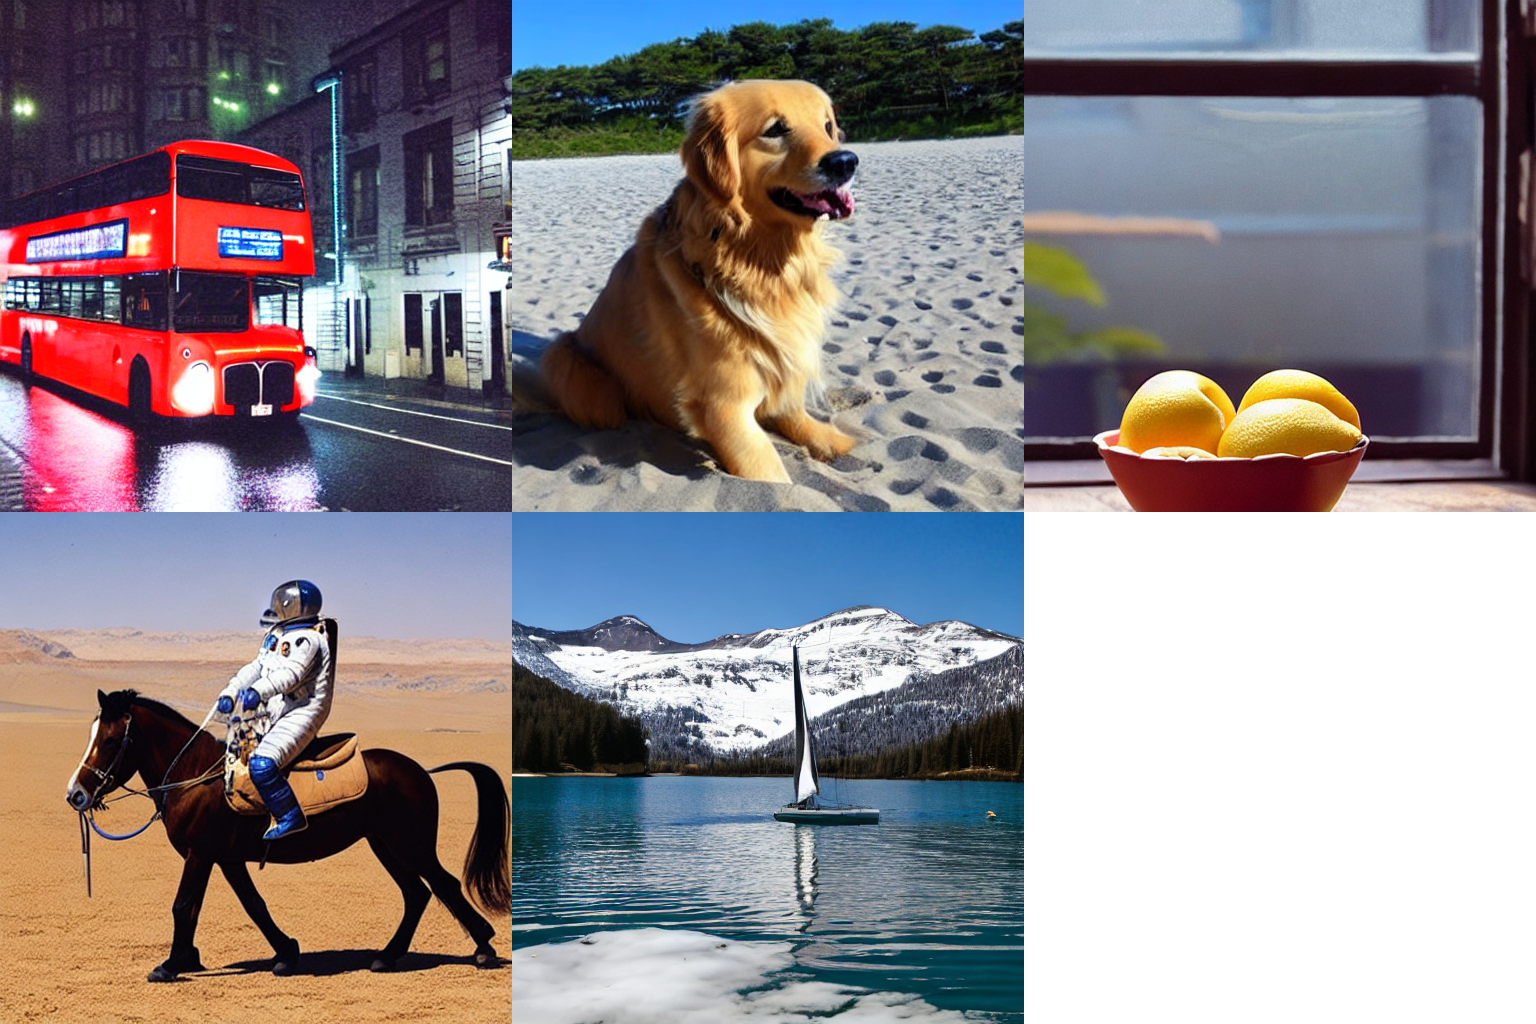

In [4]:
from IPython.display import Image as NotebookImage, display

grid_path = ROOT / "results" / "milestone1" / metadata["grid"]
display(NotebookImage(filename=str(grid_path)))

## Submission evidence

Commit the five individual PNG files, `five_prompt_grid.png`, and `runs.json` from `results/milestone1/`. The JSON file records every prompt, seed, filename, and generation setting.